# Seismic Signals Analysis

Read, inspect, and visualize seismic traces stored in HDF5 files from SPECFEM2D simulations.

This notebook demonstrates:
- Loading HDF5 seismic data files
- Inspecting file structure and metadata
- Extracting signals from multiple receivers
- Analyzing signal properties
- Plotting time-series data
- Comparing signals across different receiver stations

## 1. Import Required Libraries

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys

# Add src to path for custom utilities
sys.path.insert(0, str(Path.cwd().parent))
from src.utils.seismic_io import load_traces_from_hdf5, print_hdf5_info

print("✓ All libraries imported successfully")

In [120]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys

# Add src to path for custom utilities
sys.path.insert(0, f'/home/obandohe/JIPSENSE/JIPSENSE')
from src.utils.seismic_io import load_traces_from_hdf5, print_hdf5_info
from src.utils.fk_spectrum_class import FKSpectrum
from src.utils.Preprocessing_SW import agc_gain

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


## 2. Load HDF5 File

In [121]:
# Find the latest HDF5 file
h5_dir = Path.cwd().parent / "simulation_standard/h5"
h5_files = sorted(h5_dir.glob("*.h5"), reverse=True)

if not h5_files:
    print("❌ No HDF5 files found in h5/")
else:
    h5_file = h5_files[0]
    print(f"Loading HDF5 file: {h5_file.name}")
    
    # Load traces and metadata
    traces, metadata = load_traces_from_hdf5(h5_file)
    
    print(f"\n✓ Successfully loaded {len(traces)} traces")
    print(f"Metadata: {metadata}")

Loading HDF5 file: OUTPUT_FILES_2026-08-12_09-05-48.h5

✓ Successfully loaded 30 traces
Metadata: {'dt': np.float64(4.9e-06), 'num_traces': np.int64(30), 'source_x': np.float64(29.5), 'source_z': np.float64(27.5), 'receivers': {'S0001': {'x': 30.0, 'z': 27.0}, 'S0002': {'x': 31.0, 'z': 27.0}, 'S0003': {'x': 32.0, 'z': 27.0}, 'S0004': {'x': 33.0, 'z': 27.0}, 'S0005': {'x': 34.0, 'z': 27.0}, 'S0006': {'x': 35.0, 'z': 27.0}, 'S0007': {'x': 36.0, 'z': 27.0}, 'S0008': {'x': 37.0, 'z': 27.0}, 'S0009': {'x': 38.0, 'z': 27.0}, 'S0010': {'x': 39.0, 'z': 27.0}, 'S0011': {'x': 40.0, 'z': 27.0}, 'S0012': {'x': 41.0, 'z': 27.0}, 'S0013': {'x': 42.0, 'z': 27.0}, 'S0014': {'x': 43.0, 'z': 27.0}, 'S0015': {'x': 44.0, 'z': 27.0}, 'S0016': {'x': 45.0, 'z': 27.0}, 'S0017': {'x': 46.0, 'z': 27.0}, 'S0018': {'x': 47.0, 'z': 27.0}, 'S0019': {'x': 48.0, 'z': 27.0}, 'S0020': {'x': 49.0, 'z': 27.0}, 'S0021': {'x': 50.0, 'z': 27.0}, 'S0022': {'x': 51.0, 'z': 27.0}, 'S0023': {'x': 52.0, 'z': 27.0}, 'S0024': {'x'

## 3. Inspect File Structure

In [122]:
print_hdf5_info(h5_file)


HDF5 File: OUTPUT_FILES_2026-08-12_09-05-48.h5

Metadata:
  dt: 4.9e-06
  num_traces: 30
  source_x: 29.5
  source_z: 27.5

Traces: 30 stations
  S0001: 50000 samples, dt=0.000005s, duration=0.245s
  S0002: 50000 samples, dt=0.000005s, duration=0.245s
  S0003: 50000 samples, dt=0.000005s, duration=0.245s
  S0004: 50000 samples, dt=0.000005s, duration=0.245s
  S0005: 50000 samples, dt=0.000005s, duration=0.245s
  ... and 25 more stations

Receivers: 30 stations
  S0001: x=30.0m, z=27.0m
  S0002: x=31.0m, z=27.0m
  S0003: x=32.0m, z=27.0m
  S0004: x=33.0m, z=27.0m
  S0005: x=34.0m, z=27.0m
  ... and 25 more stations



## 4. Extract and Organize Signal Data

In [123]:
# Extract pressure signals as a 2D array (stations x time samples)
station_ids = sorted(traces.keys())
num_stations = len(traces)
num_samples = traces[station_ids[0]]['time'].shape[0]

# Create array to store all pressure data
pressure_data = np.zeros((num_stations, num_samples))

# Fill the array
for i, station_id in enumerate(station_ids):
    pressure_data[i, :] = traces[station_id]['pressure']

# Get common time array and dt
time_array = traces[station_ids[0]]['time']
dt = traces[station_ids[0]]['dt']
duration = (num_samples - 1) * dt

print(f"\n{'='*60}")
print("SIGNAL DATA SUMMARY")
print(f"{'='*60}")
print(f"Number of stations:    {num_stations}")
print(f"Number of samples:     {num_samples}")
print(f"Sampling interval (dt): {dt:.6e} seconds")
print(f"Duration:              {duration:.4f} seconds")
print(f"Time range:            {time_array[0]:.6e} to {time_array[-1]:.6e} s")
print(f"Pressure data shape:   {pressure_data.shape}")


SIGNAL DATA SUMMARY
Number of stations:    30
Number of samples:     50000
Sampling interval (dt): 4.900000e-06 seconds
Duration:              0.2450 seconds
Time range:            -6.000000e-03 to 2.389951e-01 s
Pressure data shape:   (30, 50000)


In [124]:
num_stations

30

In [125]:
# convert pressure data to obspy objects for further processing
from obspy import Trace, Stream

st = Stream(traces=[Trace(data=pressure_data[i], header={'station': station_ids[i], 'delta': dt})  for i in range(num_stations)])

st.detrend("linear")
st.taper(max_percentage=0.05, type='cosine')
st.filter("bandpass", freqmin=10, freqmax=400.0, corners=4, zerophase=True)


30 Trace(s) in Stream:

.S0001.. | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.244995Z | 204081.6 Hz, 50000 samples
...
(28 other traces)
...
.S0030.. | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.244995Z | 204081.6 Hz, 50000 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]

In [126]:
# extract the processed pressure data back to a 2D array
processed_pressure_data = np.array([tr.data for tr in st])


In [127]:
processed_pressure_data.shape

(30, 50000)

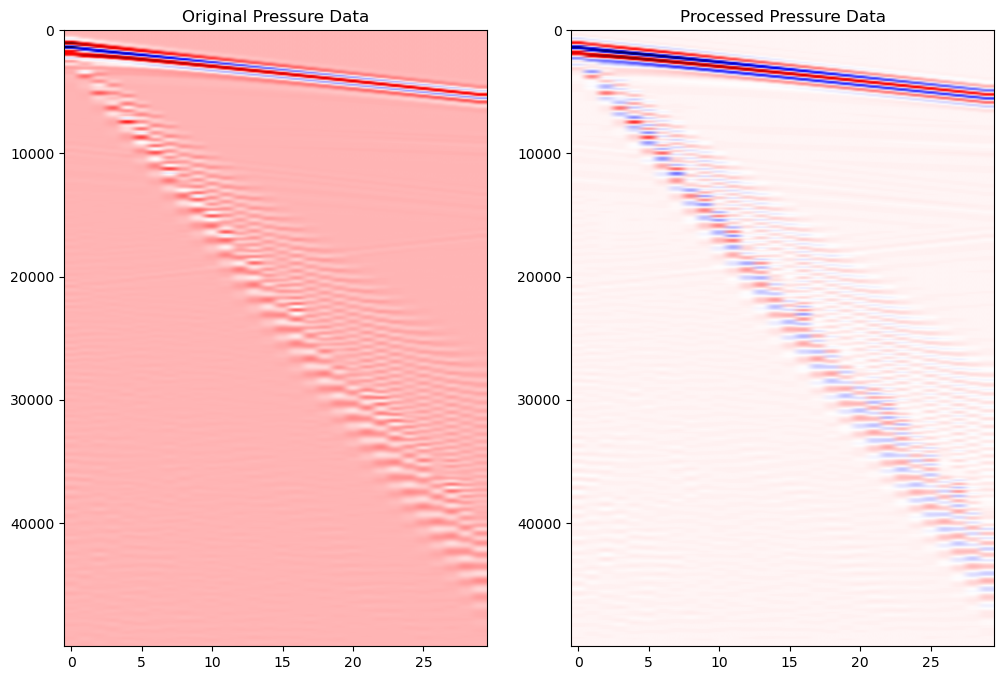

In [128]:


fig, (ax0, ax1) = plt.subplots(1,2, figsize=(12, 8), sharex=True)
ax0.imshow(pressure_data.T, aspect='auto', cmap='seismic')
ax0.set_title("Original Pressure Data")
ax1.imshow(processed_pressure_data.T, aspect='auto', cmap='seismic')
ax1.set_title("Processed Pressure Data")
plt.show()

In [129]:
for i in range(num_stations):
    traces[station_ids[i]]['pressure'] = processed_pressure_data[i]

Text(0.5, 0, 'Time (s)')

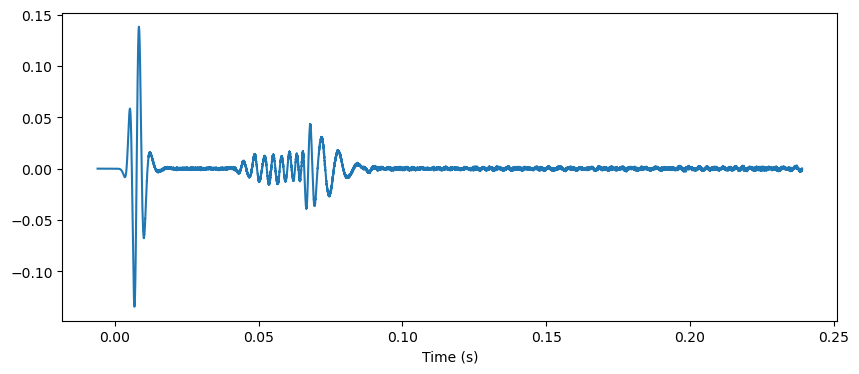

In [130]:
trace = pressure_data[10, :]
time = time_array
plt.figure(figsize=(10, 4))
plt.plot(time, trace)
plt.xlabel("Time (s)")

## 5. Analyze Signal Properties

In [131]:
# Calculate statistics for each station
stats_list = []
for station_id in station_ids:
    pressure = traces[station_id]['pressure']
    stats_list.append({
        'Station': station_id,
        'Mean': np.mean(pressure),
        'Std Dev': np.std(pressure),
        'Min': np.min(pressure),
        'Max': np.max(pressure),
        'Amplitude': np.max(np.abs(pressure))
    })

# Create DataFrame for easy viewing
stats_df = pd.DataFrame(stats_list)

print("\n" + "="*80)
print("SIGNAL STATISTICS BY STATION")
print("="*80)
print(stats_df.to_string(index=False))

# Display source and receiver information if available
print("\n" + "="*80)
print("GEOMETRY INFORMATION")
print("="*80)

if 'source_x' in metadata and 'source_z' in metadata:
    print(f"Source position: x={metadata['source_x']:.1f}m, z={metadata['source_z']:.1f}m")

if 'receivers' in metadata:
    print(f"\nReceiver positions (first 5):")
    receivers = metadata['receivers']
    for i, (station_id, coords) in enumerate(sorted(receivers.items())[:5]):
        print(f"  {station_id}: x={coords['x']:.1f}m, z={coords['z']:.1f}m")
    if len(receivers) > 5:
        print(f"  ... and {len(receivers) - 5} more receivers")


SIGNAL STATISTICS BY STATION
Station          Mean  Std Dev       Min      Max  Amplitude
  S0001 -2.715742e-06 0.011449 -0.128420 0.088044   0.128420
  S0002  1.925106e-07 0.012200 -0.115816 0.111664   0.115816
  S0003 -9.399554e-09 0.013809 -0.136183 0.132991   0.136183
  S0004  2.252246e-07 0.014486 -0.146894 0.141106   0.146894
  S0005 -1.745955e-07 0.015008 -0.148975 0.142326   0.148975
  S0006 -8.267780e-07 0.014798 -0.146119 0.140206   0.146119
  S0007 -1.605146e-06 0.014180 -0.140707 0.136427   0.140707
  S0008 -2.210596e-06 0.013866 -0.134005 0.131896   0.134005
  S0009 -1.898510e-06 0.012939 -0.126626 0.127227   0.127227
  S0010 -7.855852e-07 0.012835 -0.118886 0.122577   0.122577
  S0011  2.134347e-07 0.012262 -0.111340 0.118011   0.118011
  S0012  6.220564e-07 0.011966 -0.104453 0.113638   0.113638
  S0013  5.348297e-07 0.010990 -0.098237 0.109491   0.109491
  S0014  1.833554e-07 0.010898 -0.092631 0.105576   0.105576
  S0015  7.371133e-08 0.010239 -0.087570 0.101902   0.1

In [132]:
pressure.shape

(50000,)

## 6. Plot Individual Time-Series Signals

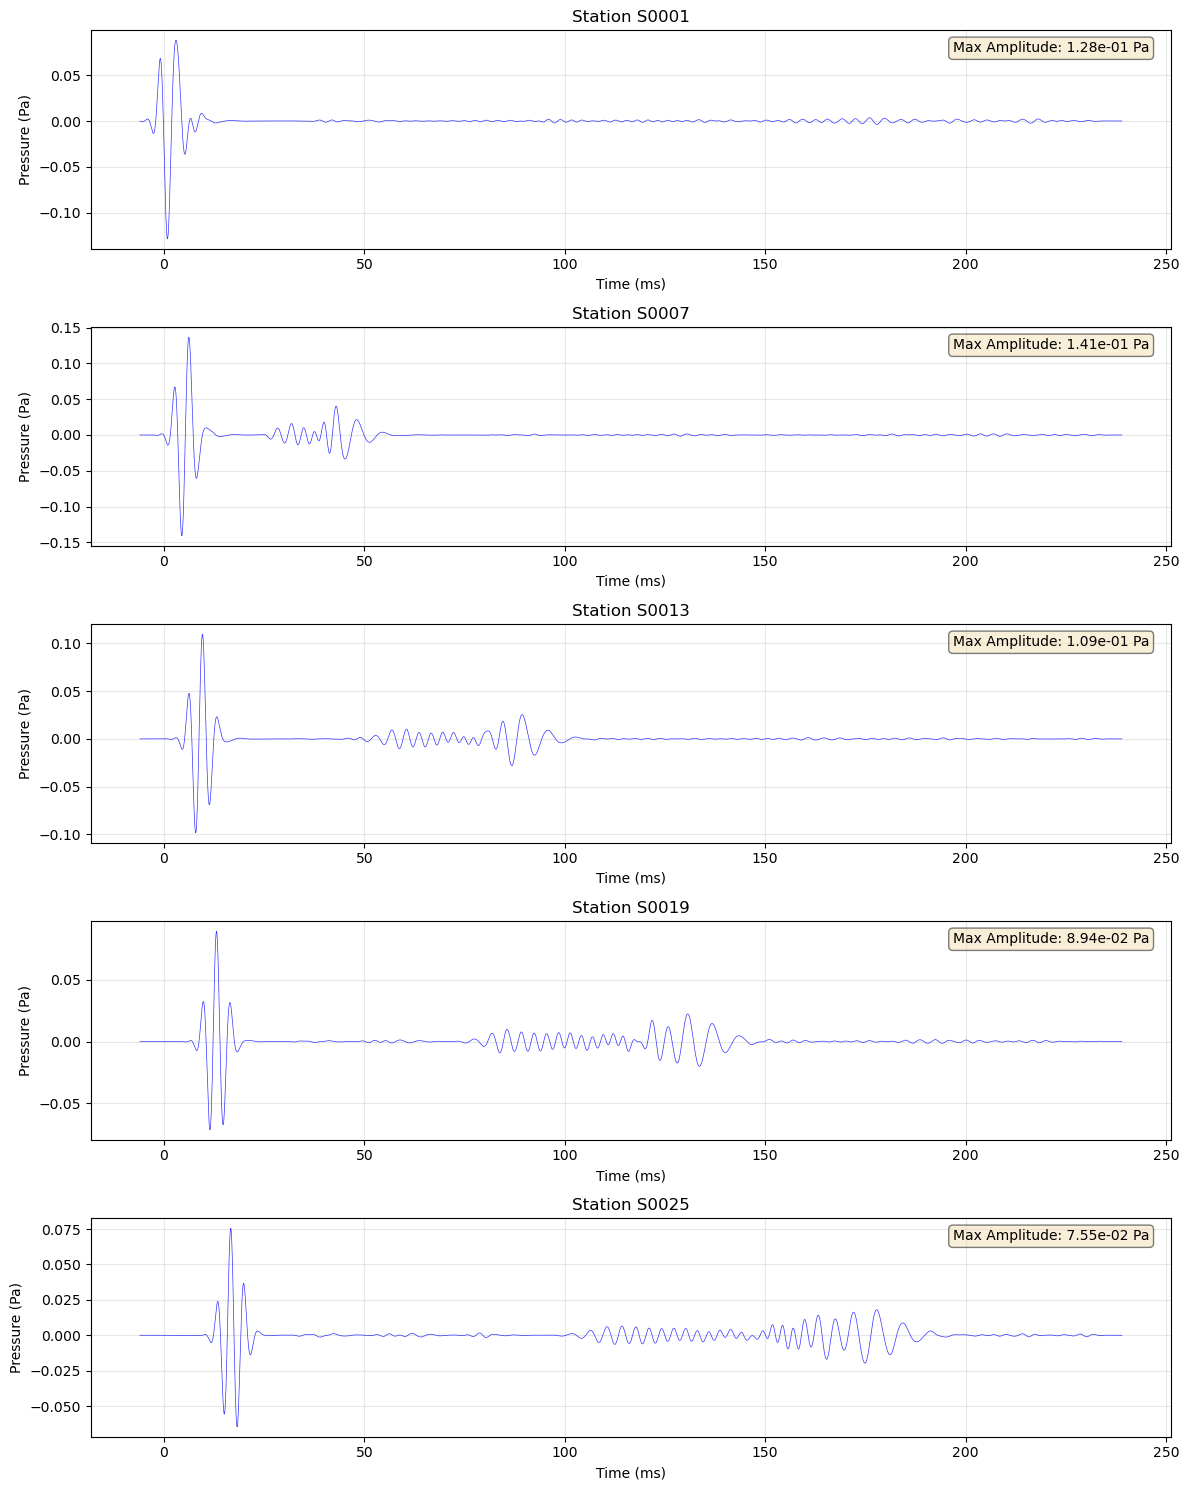

In [133]:
# Select a few stations to plot
selected_stations = station_ids[::6]  # Every 6th station
num_plots = len(selected_stations)

fig, axes = plt.subplots(num_plots, 1, figsize=(12, 3*num_plots))
if num_plots == 1:
    axes = [axes]

for idx, (ax, station_id) in enumerate(zip(axes, selected_stations)):
    time = traces[station_id]['time']
    pressure = traces[station_id]['pressure']
    
    ax.plot(time * 1000, pressure, 'b-', linewidth=0.5, alpha=0.8)
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Pressure (Pa)')
    ax.set_title(f'Station {station_id}')
    ax.grid(True, alpha=0.3)
    
    # Add statistics to title
    max_pressure = np.max(np.abs(pressure))
    ax.text(0.98, 0.95, f'Max Amplitude: {max_pressure:.2e} Pa',
            transform=ax.transAxes, ha='right', va='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

## 7. All Signals Comparison (Normalized)

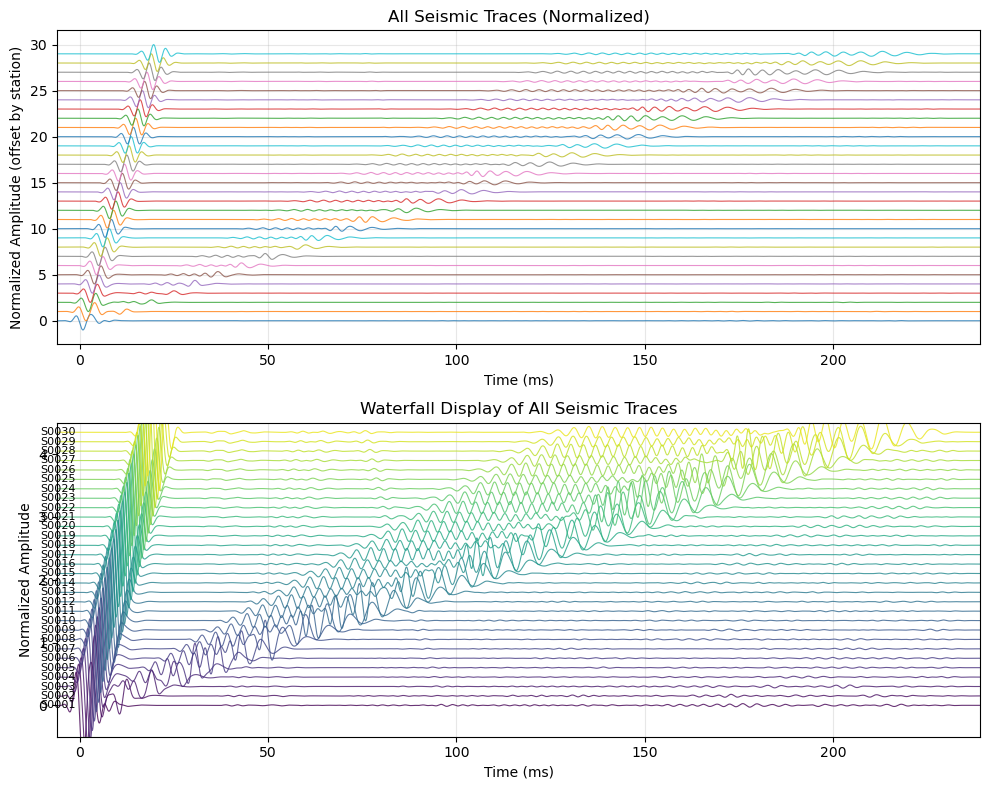

In [134]:
# Plot all signals normalized by their maximum amplitude
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Plot 1: Normalized traces
time_ms = time_array * 1000
for i, station_id in enumerate(station_ids):
    pressure = traces[station_id]['pressure']
    max_pressure = np.max(np.abs(pressure))
    normalized = pressure / max_pressure if max_pressure > 0 else pressure
    ax1.plot(time_ms, normalized + i, label=f'{station_id}', linewidth=0.8, alpha=0.8)

ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Normalized Amplitude (offset by station)')
ax1.set_title('All Seismic Traces (Normalized)')
ax1.grid(True, alpha=0.3)
ax1.set_xlim(time_ms[0], time_ms[-1])

# Plot 2: Waterfall style (stacked)
for i, station_id in enumerate(station_ids):
    pressure = traces[station_id]['pressure']
    max_pressure = np.max(np.abs(pressure))
    normalized = pressure / max_pressure if max_pressure > 0 else pressure
    offset = i * 0.15  # Offset for better visibility
    ax2.plot(time_ms, normalized + offset, color=plt.cm.viridis(i/len(station_ids)), 
            linewidth=0.8, alpha=0.8)
    ax2.text(-1, offset, station_id, fontsize=8, ha='right', va='center')

ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Normalized Amplitude')
ax2.set_title('Waterfall Display of All Seismic Traces')
ax2.grid(True, alpha=0.3, axis='x')
ax2.set_xlim(time_ms[0], time_ms[-1])
ax2.set_ylim(-0.5, len(station_ids) * 0.15)

plt.tight_layout()
plt.show()

## 8. Receiver and Source Geometry Visualization

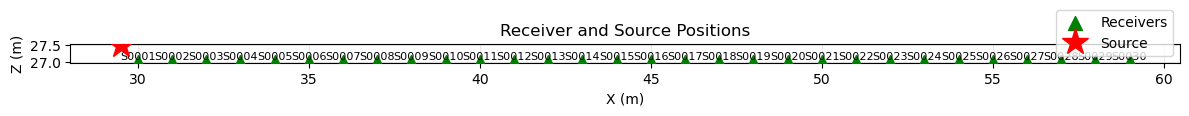

In [135]:
if 'receivers' in metadata:
    fig, ax = plt.subplots(figsize=(12, 4))
    
    receivers = metadata['receivers']
    rx_x = [receivers[station_id]['x'] for station_id in sorted(receivers.keys())]
    rx_z = [receivers[station_id]['z'] for station_id in sorted(receivers.keys())]
    
    # Plot receivers
    ax.scatter(rx_x, rx_z, c='green', s=100, marker='^', label='Receivers', zorder=3)
    
    # Add station labels
    for station_id in sorted(receivers.keys()):
        x = receivers[station_id]['x']
        z = receivers[station_id]['z']
        ax.text(x, z + 0.05, station_id, ha='center', fontsize=8)
    
    # Plot source
    if 'source_x' in metadata and 'source_z' in metadata:
        ax.plot(metadata['source_x'], metadata['source_z'], 'r*', markersize=20, 
               label='Source', zorder=4)
    
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Z (m)')
    ax.set_title('Receiver and Source Positions')
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()
    plt.show()
else:
    print("⚠️  Receiver geometry not available in metadata")

## 9. Frequency Analysis (Bonus)

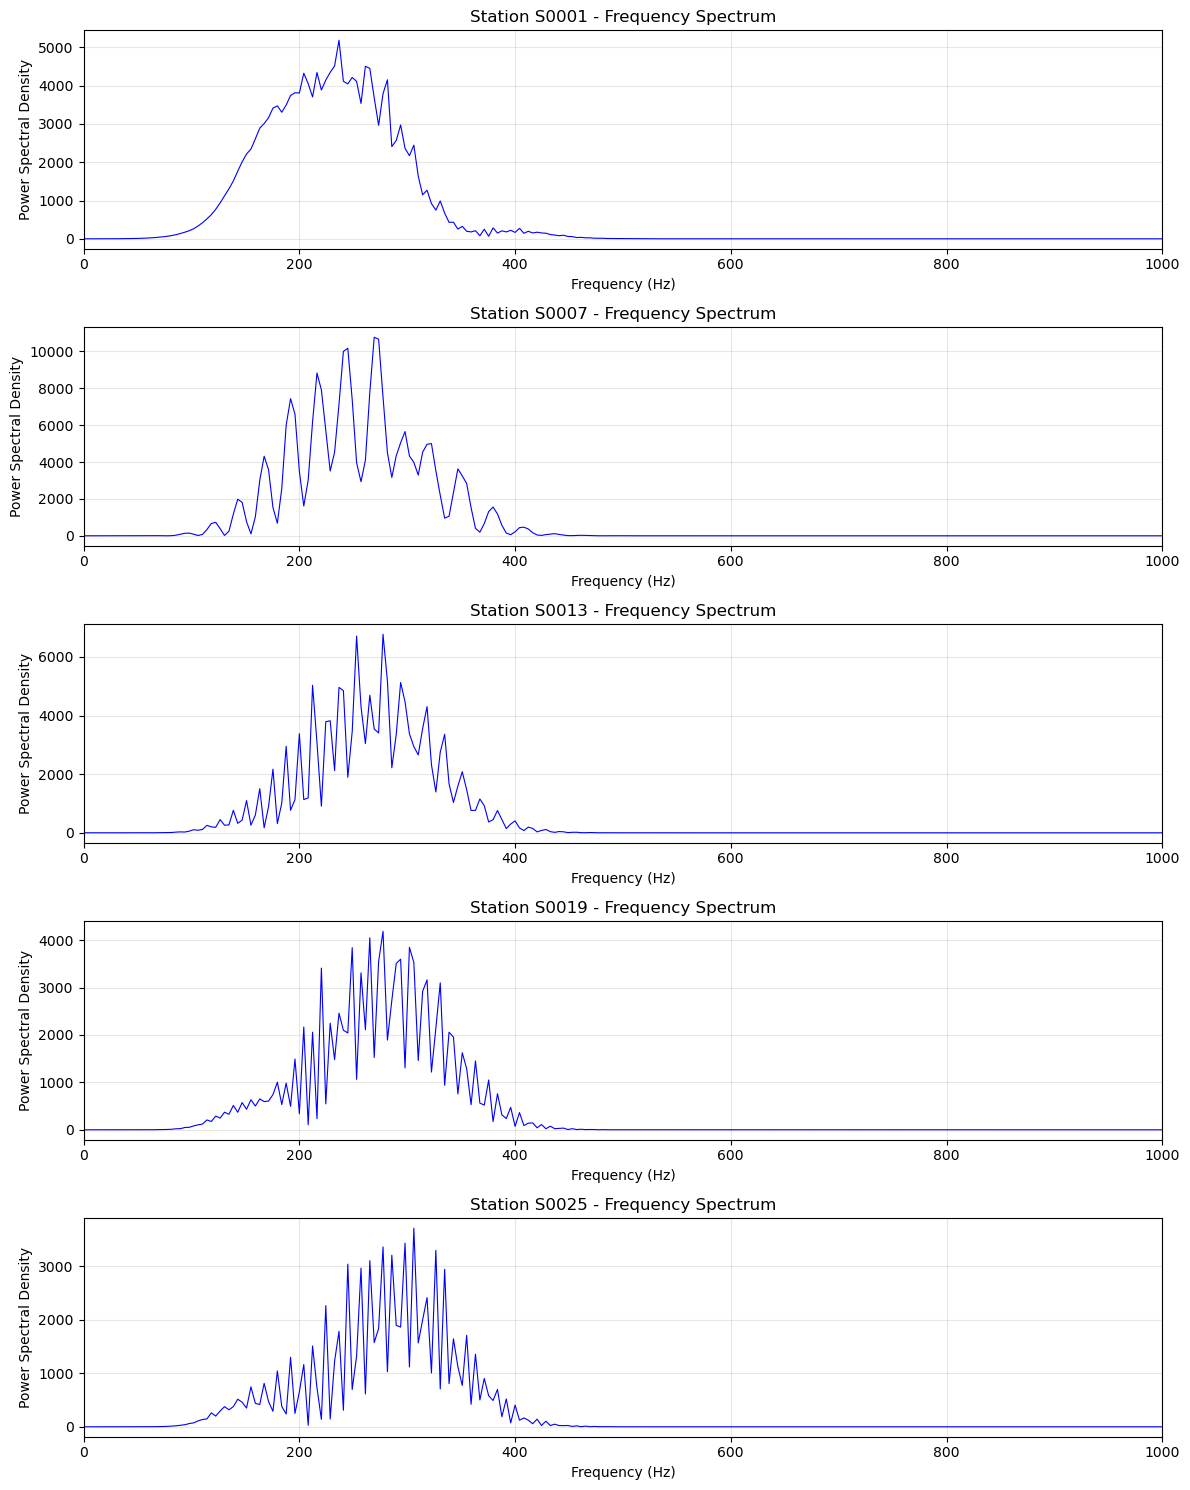


Frequency range: 0 to 102036.7 Hz
Frequency resolution: 4.08 Hz


In [136]:
# Compute FFT for selected stations
fig, axes = plt.subplots(len(selected_stations), 1, figsize=(12, 3*len(selected_stations)))
if len(selected_stations) == 1:
    axes = [axes]

freq_hz = np.fft.fftfreq(num_samples, dt)
freq_hz = freq_hz[:num_samples//2]  # Only positive frequencies

for ax, station_id in zip(axes, selected_stations):
    pressure = traces[station_id]['pressure']
    
    # Compute FFT
    fft_data = np.fft.fft(pressure)
    power = np.abs(fft_data[:num_samples//2]) ** 2
    

    ax.plot(freq_hz, power, 'b-', linewidth=0.8)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power Spectral Density')
    ax.set_title(f'Station {station_id} - Frequency Spectrum')
    ax.grid(True, alpha=0.3, which='both')
    ax.set_xlim(0, min(1000, freq_hz[-1]))  # Limit to 1000 Hz for clarity

plt.tight_layout()
plt.show()

print(f"\nFrequency range: 0 to {freq_hz[-1]:.1f} Hz")
print(f"Frequency resolution: {freq_hz[1] - freq_hz[0]:.2f} Hz")

In [137]:
pressure_data.shape

(30, 50000)

In [138]:
# compute a fk spectrum

# apply AGC to the filtered data
shotgather = pressure_data.T  # Assuming pressure_data is the shot gather
agc_gate = 0.22 # seconds
fs = 1/dt  # Sampling frequency in Hz
dx = 1.0  # receiver spacing in meters
sg_agc = agc_gain(shotgather, fs, agc_gate,method='amplitude')

# Initialize FK spectrum object
fk = FKSpectrum(dx=dx,dt=dt)
FK, f, k, _, _ = fk.compute(sg_agc)


/tmp/ipykernel_5848/2527337919.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "w--" (-> color='w'). The keyword argument will take precedence.
  plt.plot(-k_line,f_line, 'w--', label=f'v={v} m/s',color='white')
/tmp/ipykernel_5848/2527337919.py:20: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "w-." (-> color='w'). The keyword argument will take precedence.
  plt.plot(-k_line_soil, f_line_soil, 'w-.', label=f'v={v_soil} m/s',color='blue')


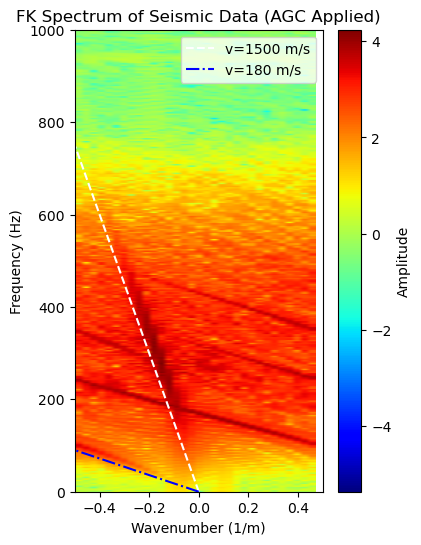

In [139]:
# plot fk spectrum
plt.figure(figsize=(4, 6))
plt.imshow(np.log10(np.abs(FK)), extent=[k[0], k[-1], f[0], f[-1]], aspect='auto', origin='lower', cmap='jet')
plt.colorbar(label='Amplitude')
plt.title('FK Spectrum of Seismic Data (AGC Applied)')
plt.xlabel('Wavenumber (1/m)')
plt.ylabel('Frequency (Hz)')
plt.ylim(0,1000)  # Limit frequency axis to 1000 Hz for better visibility

# add a slopeline to indicate the expected dispersion curve
v = 1500  # m/s, example velocity
f_line = np.linspace(0, 1000, 100)
k_line = f_line / v

v_soil = 180 # m/s, example velocity for soil
f_line_soil = np.linspace(0, 1000, 100)
k_line_soil = f_line_soil / v_soil

plt.plot(-k_line,f_line, 'w--', label=f'v={v} m/s',color='white')
plt.plot(-k_line_soil, f_line_soil, 'w-.', label=f'v={v_soil} m/s',color='blue')
plt.legend()

plt.xlim(-0.5, 0.5)  # Limit wavenumber axis for better visibility

plt.show()